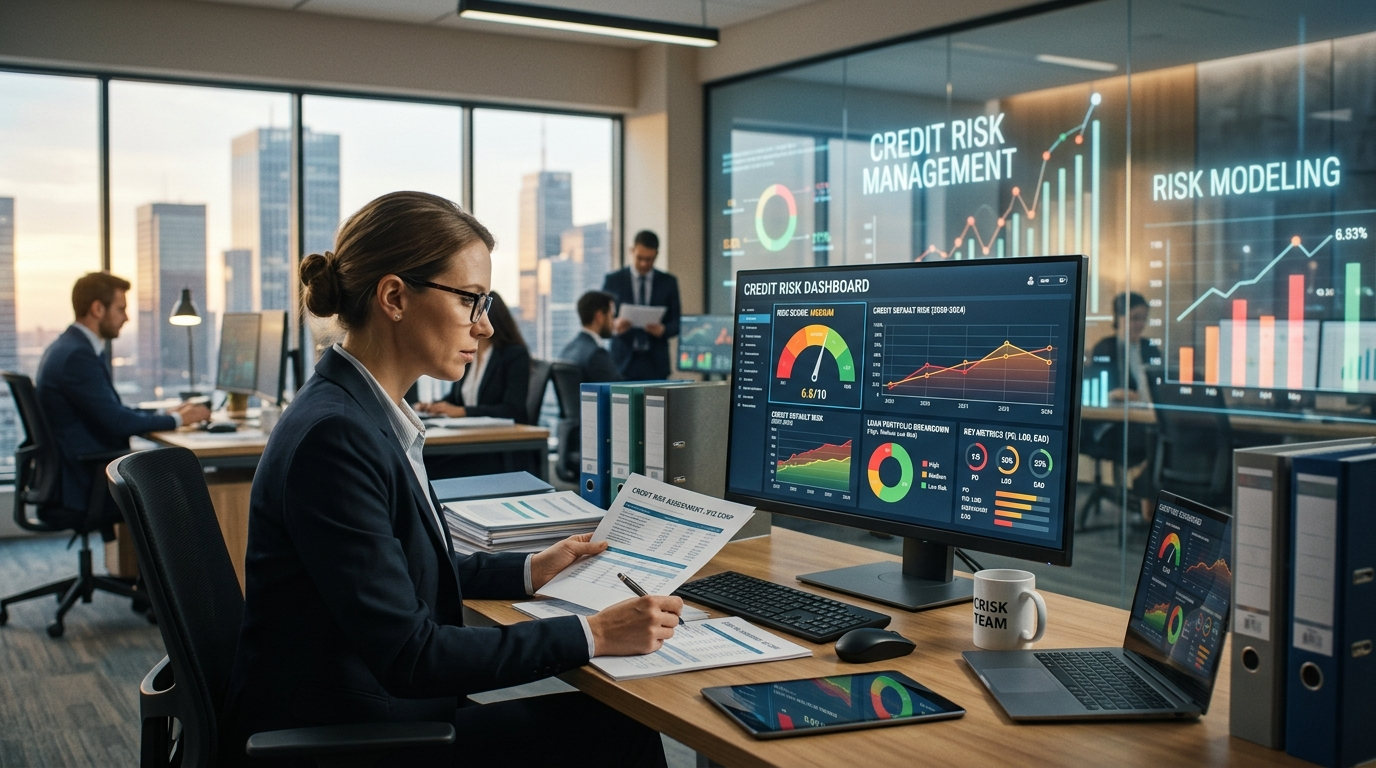

   # Credit Risk & Decision Optimization

## Business Importance

Credit risk analytics is a cornerstone of modern financial decision-making, with direct implications for profitability, regulatory compliance, and institutional stability.

Credit risk analytics helps financial institutions improve
portfolio quality, manage potential credit losses, allocate
capital more efficiently, and establish data-driven lending
policies.

## Business Problem

Financial institutions face a critical and ongoing dilemma: how to aggressively expand their loan portfolios to drive revenue while strictly minimizing exposure to credit risk and Non-Performing Loans (NPLs). Traditional, rule-based underwriting often fails to capture the nuanced risk profiles of modern borrowers, leading to suboptimal lending decisions.

## Project Objective

The goal of this project is to develop a robust, data-driven predictive and analytical framework. By accurately forecasting default probabilities and optimizing risk thresholds, this framework will enable financial institutions to automate underwriting, maximize portfolio profitability, and ensure fair, compliant, and scalable credit decisions.

## Extrating the Dataset

In [ ]:
# Importing libraries 

import pandas as pd
from sqlalchemy import create_engine, text

# AWS RDS connection string
engine = create_engine(
    "postgresql+psycopg2://credit_analyst:********@"
    "credit-db.xxxxxxxx.us-east-1.rds.amazonaws.com:5432/creditdb"
)

# Query
query = text("""
    SELECT
        l.loan_id,
        b.annual_income,
        b.employment_length,
        b.debt_to_income_pct,
        l.loan_amount,
        l.loan_term_months,
        l.interest_rate_pct,
        b.credit_score,
        b.num_credit_lines,
        b.credit_utilization,
        b.num_delinquencies_2y,
        b.num_public_records,
        b.age,
        b.home_ownership,
        l.loan_purpose,
        CASE WHEN l.loan_status = 'DEFAULT' THEN 1 ELSE 0 END AS default,
        m.pd_true
    FROM lending.loans     AS l
    JOIN lending.borrowers AS b ON l.borrower_id = b.borrower_id
    JOIN lending.pd_models AS m ON l.loan_id     = m.loan_id
    WHERE l.issue_date >= DATE '2020-01-01'
    ORDER BY l.loan_id
""")

# Creating the final dataset
with engine.connect() as conn:
    df = pd.read_sql(query, conn)

### Dataset Explanation

| Column | Description |
| :--- | :--- |
| `loan_id` | Unique identifier for each loan, used only as a key. |
| `annual_income` | Applicant's gross annual income in USD, used to measure repayment capacity. |
| `employment_length` | Number of years the applicant has been employed at their current job, an indicator of job stability. |
| `debt_to_income_pct` | Percentage of monthly debt relative to monthly income, measuring how leveraged the applicant is. |
| `loan_amount` | Total loan amount requested in USD. |
| `loan_term_months` | Loan term expressed in months (12, 24, 36, 48, or 60). |
| `interest_rate_pct` | Annual interest rate assigned to the loan, higher for riskier applicants. |
| `credit_score` | FICO-like credit score (300–850) summarizing the applicant's credit history. |
| `num_credit_lines` | Number of open credit lines the applicant has. |
| `credit_utilization` | Proportion (0–1) of available credit currently being used by the applicant. |
| `num_delinquencies_2y` | Number of late payments the applicant had in the last 2 years. |
| `num_public_records` | Number of negative public records (bankruptcies, liens, etc.). |
| `age` | Applicant's age in years. |
| `home_ownership` | Applicant's housing status: RENT (renting), MORTGAGE (mortgage), or OWN (owns outright). |
| `loan_purpose` | Reason for the loan (debt consolidation, home improvement, major purchase, medical, small business, education). |
| `default` | Target: whether the applicant defaulted (1 = did not pay / defaulted, 0 = paid as agreed). |
| `pd_true` | True probability of default used internally to generate the default label. |

### Dataset Schema 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7682 entries, 0 to 7681
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   loan_id               7682 non-null   object 
 1   annual_income         7682 non-null   int64  
 2   employment_length     7682 non-null   int64  
 3   debt_to_income_pct    7682 non-null   float64
 4   loan_amount           7682 non-null   int64  
 5   loan_term_months      7682 non-null   int64  
 6   interest_rate_pct     7682 non-null   float64
 7   credit_score          7682 non-null   int64  
 8   num_credit_lines      7682 non-null   int64  
 9   credit_utilization    7682 non-null   float64
 10  num_delinquencies_2y  7682 non-null   int64  
 11  num_public_records    7682 non-null   int64  
 12  age                   7682 non-null   int64  
 13  home_ownership        7682 non-null   object 
 14  loan_purpose          7682 non-null   object 
 15  default              

### First five rows

In [5]:
df.head()

,loan_id,annual_income,employment_length,debt_to_income_pct,loan_amount,loan_term_months,interest_rate_pct,credit_score,num_credit_lines,credit_utilization,num_delinquencies_2y,num_public_records,age,home_ownership,loan_purpose,default,pd_true
0,LN000001,23500,6,56.4,16000,24,14.63,574,6,0.645,8,0,41,MORTGAGE,HOME_IMPROVEMENT,1,0.9822
1,LN000002,37300,15,53.1,22700,24,14.18,656,6,0.629,0,0,47,OWN,DEBT_CONSOLIDATION,0,0.4257
2,LN000003,25000,2,37.7,11800,36,12.11,621,5,0.538,2,0,28,RENT,MAJOR_PURCHASE,1,0.6453
3,LN000004,117500,24,2.9,2700,12,8.44,850,6,0.210,0,0,48,OWN,HOME_IMPROVEMENT,0,0.0022
4,LN000005,29100,8,66.0,16400,36,16.03,439,5,0.838,7,0,18,RENT,MAJOR_PURCHASE,1,0.9993


## Data Analysis

In [7]:
# Importing data visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns

### Credit Score vs Interest Rate (split by default)

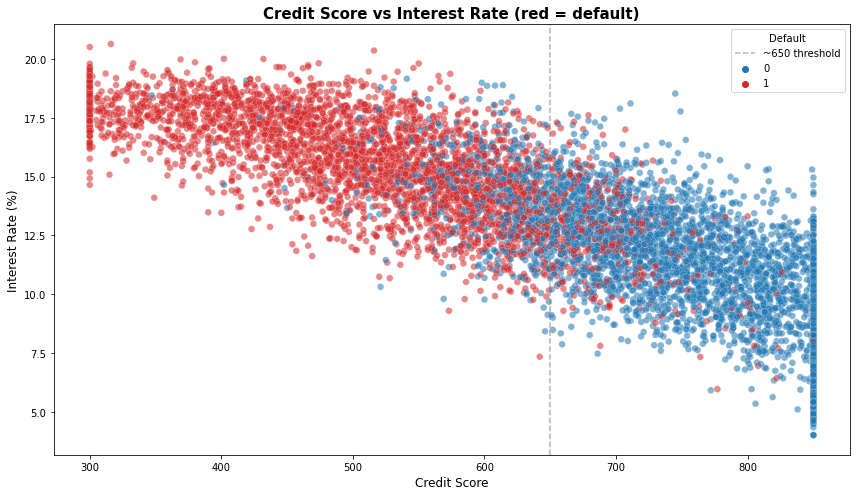

In [9]:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x="credit_score",
    y="interest_rate_pct",
    hue="default",
    palette={0: "#1f77b4", 1: "#d62728"},
    alpha=0.55,
    s=45,
    edgecolor="white",
    linewidth=0.3,
)
plt.title("Credit Score vs Interest Rate (red = default)", fontsize=15, weight="bold")
plt.xlabel("Credit Score", fontsize=12)
plt.ylabel("Interest Rate (%)", fontsize=12)
plt.axvline(x=650, color="gray", linestyle="--", alpha=0.6, label="~650 threshold")
plt.legend(title="Default", loc="upper right")
plt.tight_layout()
plt.show()

Conclusion: Credit score is a very strong warning sign. If a borrower's score is below 650, the risk of them not paying back the loan goes up significantly. Lenders should be very careful when approving loans for people in this range.

### Debt-to-Income distribution by Default

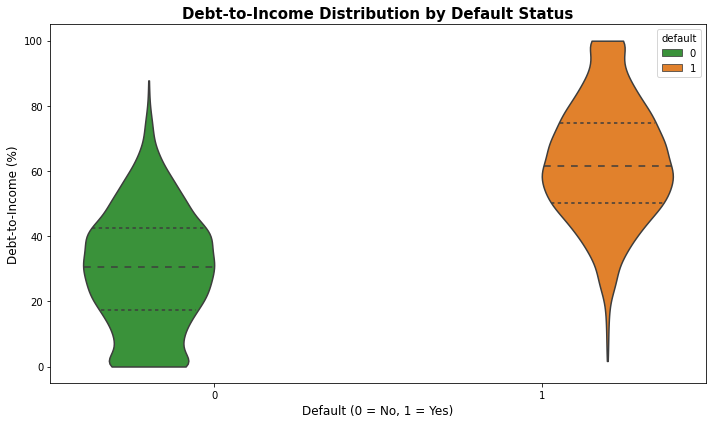

In [10]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df,
    x="default",
    y="debt_to_income_pct",
    hue="default",
    palette={0: "#2ca02c", 1: "#ff7f0e"},
    inner="quartile",
    cut=0,
    legend=False,
)
plt.title("Debt-to-Income Distribution by Default Status", fontsize=15, weight="bold")
plt.xlabel("Default (0 = No, 1 = Yes)", fontsize=12)
plt.ylabel("Debt-to-Income (%)", fontsize=12)
plt.tight_layout()
plt.show()

Conclusion: Debt-to-Income (DTI) is another very clear warning sign. If a borrower's DTI is high (above 50-60%), the risk of them not paying back the loan goes up significantly. Lenders should be cautious when approving loans for people with high debt loads.

### Correlation Heatmap

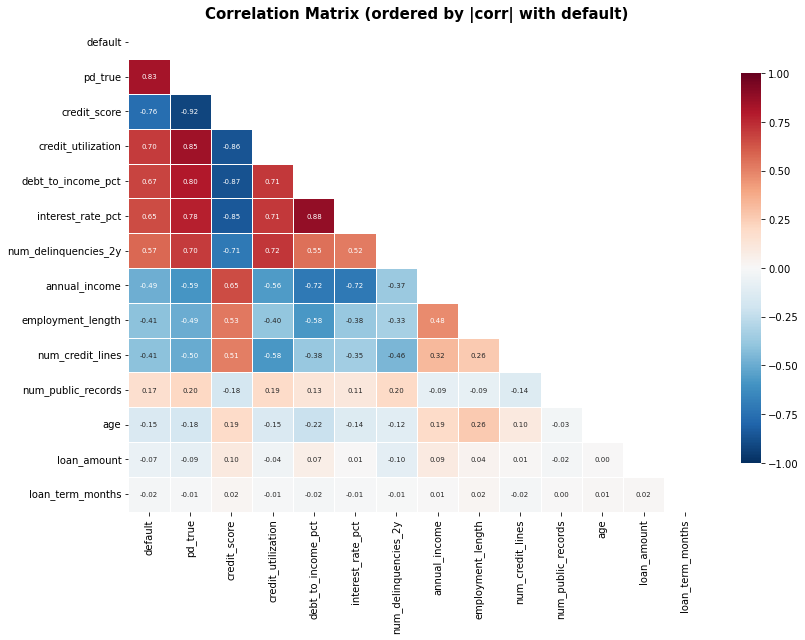

In [16]:
import numpy as np

num_cols = df.select_dtypes(include=np.number).columns
corr = df[num_cols].corr()

order = corr["default"].abs().sort_values(ascending=False).index
corr = corr.loc[order, order]

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Matrix (ordered by |corr| with default)", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

Conclusion: The correlation matrix tells us exactly which features matter most for predicting default and which ones we can safely ignore.

Focus on: Credit score, credit utilization, debt-to-income ratio, interest rate, and recent delinquencies. These are the real drivers of risk.

## Statistical Analysis

### Predicting whether customer will be in default by logistic regression

In [27]:
# Importing libraries

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score)

# Selecting the columns for predecting
features = ["credit_score", "debt_to_income_pct", "annual_income",
            "loan_amount", "employment_length", "num_delinquencies_2y",
            "credit_utilization", "interest_rate_pct"]

df["default"] = df["default"].astype(int)

# X will predict Y
X = df[features]
y = df["default"]

#Training the ML model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

# Scale only for numerical stability in statsmodels
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

model = sm.Logit(y_train, sm.add_constant(X_train_s)).fit(disp=0)

p_test = model.predict(sm.add_constant(X_test_s))

print(f"\nAUC (Area Under the Curve) on {roc_auc_score(y_test, p_test):.3f} out of 1")

print("\nFull classification report:")
print(classification_report(y_test, y_pred, digits=3,
                                target_names=["No default", "Default"]))


AUC (Area Under the Curve) on 0.955 out of 1

Full classification report:
              precision    recall  f1-score   support

  No default      0.937     0.813     0.871      1044
     Default      0.808     0.935     0.867       877

    accuracy                          0.869      1921
   macro avg      0.872     0.874     0.869      1921
weighted avg      0.878     0.869     0.869      1921



AUC = 0.955 out of 1.0. A very strong result. It means the model is excellent at telling apart borrowers who will default from those who won't.

Recall on Default = 93.5%. The model catches 93.5% of all actual defaulters. So a few bad loans get approved.

Precision on Default = 80.8%. Of the people the model flags as "risky," about 19% are actually good borrowers who got unfairly rejected.

### Noticing the columns more significant in our analysis

In [23]:
# Importing the libraries

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

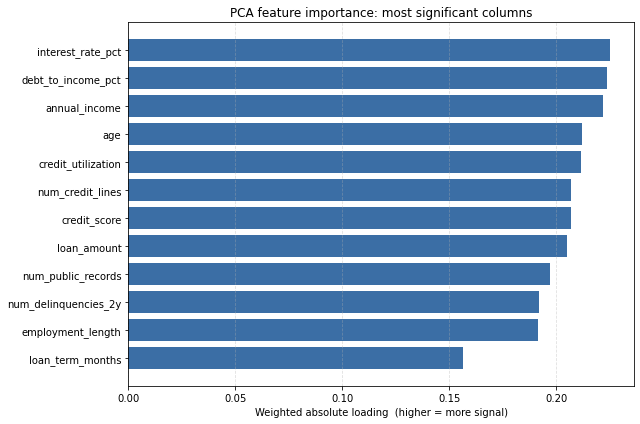

In [29]:
# Getting just the numeric columns
numeric_cols = [
    "annual_income", "employment_length", "debt_to_income_pct",
    "loan_amount", "loan_term_months", "interest_rate_pct",
    "credit_score", "num_credit_lines", "credit_utilization",
    "num_delinquencies_2y", "num_public_records", "age",
]

# Training the PCA
X = df[numeric_cols].copy()
X["annual_income"] = np.log1p(X["annual_income"])
X["loan_amount"]   = np.log1p(X["loan_amount"])

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=0.80, random_state=42).fit(X_scaled)

loadings = pd.DataFrame(pca.components_.T, index=numeric_cols)
importance = (loadings.abs() * pca.explained_variance_ratio_).sum(axis=1).sort_values()

# Making the chart
plt.figure(figsize=(9, 6))
plt.barh(importance.index, importance.values, color="#3b6ea5")
plt.xlabel("Weighted absolute loading  (higher = more signal)")
plt.title("PCA feature importance: most significant columns")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


This PCA chart illustrates how much each original feature contributes to the main patterns in the data. The analysis reveals that: `interest rate`, `debt-to-income ratio`, and `annual income` are the dominant drivers of credit risk, forming a "big three" that could power a highly effective simplified model. 

While `age` and `credit utilization` also serve as strong signals that shouldn't be ignored, variables like `loan term` and `employment length` add very little predictive value and could be safely dropped to streamline the model without sacrificing accuracy.

### Retraining the Logistic Regression but only with the most three important columns

In [44]:
features = ["interest_rate_pct", "debt_to_income_pct", "annual_income"]

df["default"] = df["default"].astype(int)

X = df[features]
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

# Fit statsmodels Logit model
model = sm.Logit(y_train, sm.add_constant(X_train_s)).fit(disp=0)

# Evaluation
p_test = model.predict(sm.add_constant(X_test_s))
y_pred = (p_test >= 0.5).astype(int)

print(f"\nAUC: {roc_auc_score(y_test, p_test):.3f}")




AUC: 0.902


### Creating our own Credit Default Predictor

In [56]:
# Customer information
interest_rate_pct  = 50.5
debt_to_income_pct = 35.0
annual_income      = 100000

# Inputs Standarization
row = pd.DataFrame([{
    "interest_rate_pct":  interest_rate_pct,
    "debt_to_income_pct": debt_to_income_pct,
    "annual_income":      annual_income,
}])

row_s = scaler.transform(row[features])
row_s_const = sm.add_constant(row_s, has_constant='add')

# Prediction
prob = model.predict(row_s_const)[0]
pred = int(prob >= 0.5)

pred = "✔️" if pred == 0 else "❌"

print(f"\nProbability of default : {prob:.2%}")
print(f"Decision               : {pred}")


Probability of default : 99.93%
Decision               : ❌
